# Generating correlated returns

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. Random experiments use the displayed integer seeds with Julia’s `Xoshiro` generator, so their realized samples differ from NumPy. Public observations use the same stated data sources. Figures use the requested dark theme, and Julia outputs are saved under `outputs/julia`.

A correlated random vector is formed by shifting and linearly combining independent standard-normal shocks:

$$
X=\mu+LZ,\qquad Z\sim\mathcal N(0,I_p),\qquad
\operatorname{Cov}(X)=LL^{\mathsf T}=\Sigma.
$$

Here, $X$ is the simulated $p$-dimensional vector; $\mu$ is its mean; $L$ is a square-root matrix of the covariance. $Z$ is a $p$-dimensional standard-normal vector; $I_p$ is the $p\times p$ identity matrix; $\Sigma$ is the covariance matrix.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("02_synthetic_financial_environments");


## Equicorrelation Blocks

The matrix has unit variances and one common correlation, with one large eigenvalue and $m-1$ equal smaller ones:

$$
B_m(\rho)=(1-\rho)I_m+\rho\mathbf 1_m\mathbf 1_m^{\mathsf T},\qquad
\lambda(B_m)=\{1+(m-1)\rho,\underbrace{1-\rho,\ldots,1-\rho}_{m-1}\}.
$$

Here, $B_m(\rho)$ is an $m\times m$ equicorrelation matrix; $\rho$ is the common off-diagonal correlation. $I_m$ is the identity matrix; $\mathbf 1_m$ is a vector of $m$ ones; $\lambda(B_m)$ is the set of eigenvalues; $m$ is block size.

In [2]:
block_count, block_size, within_block_correlation = 4, 5, 0.65
dimension = block_count*block_size
block_correlation = RiskLabAI.Data.form_block_matrix(block_count, block_size, within_block_correlation)
block_eigenvalues = eigvals(Symmetric(block_correlation))
true_mean_vector, true_covariance = RiskLabAI.Data.form_true_matrix(block_count, block_size, within_block_correlation; rng=Xoshiro(20260926))
true_mean = reshape(true_mean_vector, :, 1)
true_standard_deviation = sqrt.(diag(true_covariance))
true_correlation = true_covariance./(true_standard_deviation*true_standard_deviation')
factor_covariance = RiskLabAI.Data.random_cov(dimension, 3; rng=Xoshiro(20260927))
covariance_design = DataFrame("Design quantity"=>["Dimension", "Number of blocks", "Assets per block", "Within-block correlation", "Smallest block eigenvalue", "Largest block eigenvalue", "Factor covariance rank contribution", "Smallest factor covariance eigenvalue"], "Value"=>[dimension, block_count, block_size, within_block_correlation, minimum(block_eigenvalues), maximum(block_eigenvalues), 3, minimum(eigvals(Symmetric(factor_covariance)))])
save_table(covariance_design, paths, "covariance_design"; caption="Design quantities for the structured and factor covariance generators.", label="tab:covariance-design")
save_data(DataFrame(factor_covariance, :auto), paths, "factor_covariance");


Row,Design quantity,Value
,String,Float64
1,Dimension,20.0
2,Number of blocks,4.0
3,Assets per block,5.0
4,Within-block correlation,0.65
5,Smallest block eigenvalue,0.35
6,Largest block eigenvalue,3.6
7,Factor covariance rank contribution,3.0
8,Smallest factor covariance eigenvalue,0.0946278


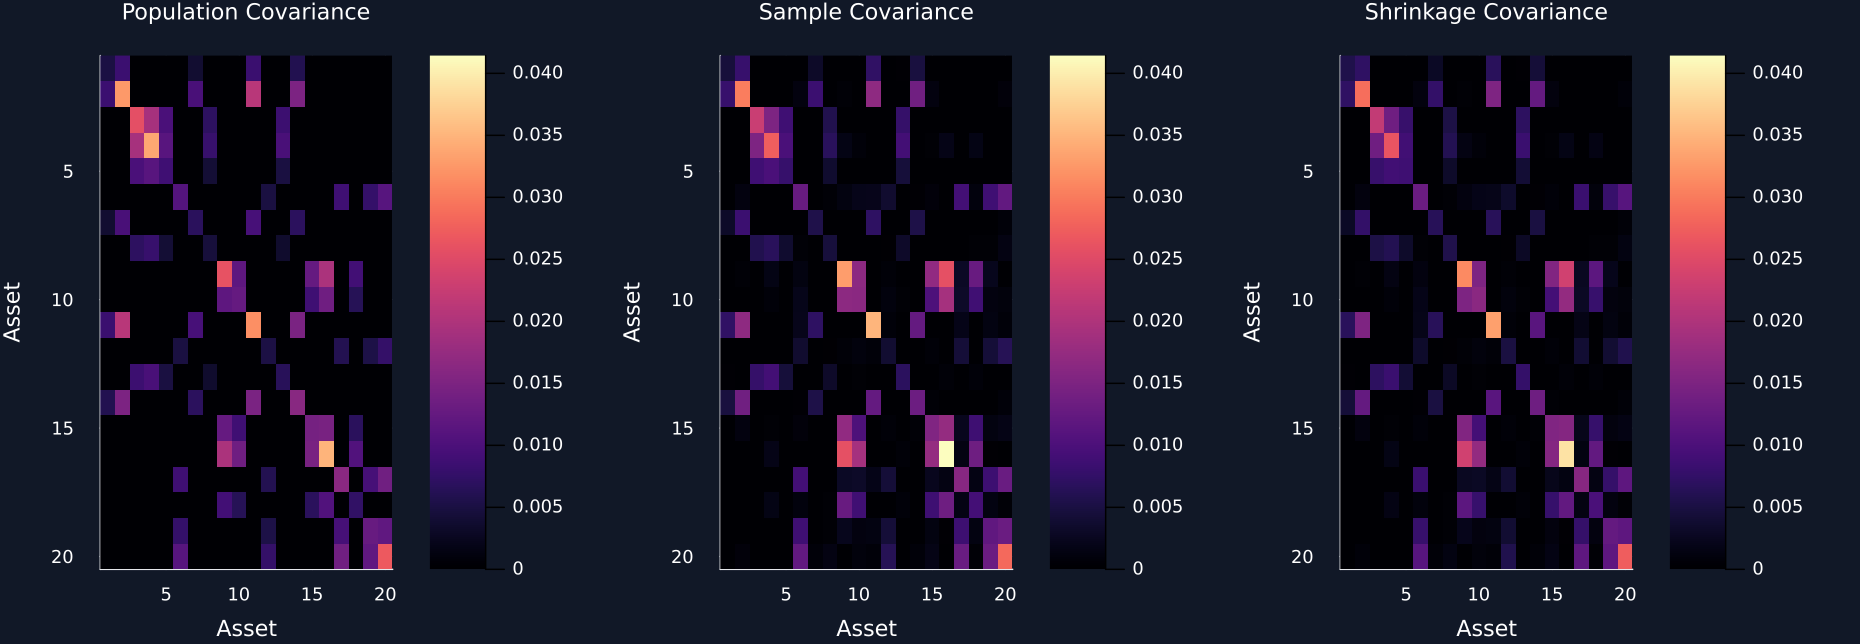

In [3]:
sample_mean, sample_covariance = RiskLabAI.Data.simulates_cov_mu(true_mean, true_covariance, 120; shrink=false, rng=Xoshiro(20260928))
shrinkage_mean, shrinkage_covariance = RiskLabAI.Data.simulates_cov_mu(true_mean, true_covariance, 120; shrink=true, rng=Xoshiro(20260928))
covariance_limit = max(maximum(true_covariance), maximum(sample_covariance), maximum(shrinkage_covariance))
matrices = [true_covariance, sample_covariance, shrinkage_covariance]
titles = ["Population Covariance", "Sample Covariance", "Shrinkage Covariance"]
panels = [heatmap(matrix; color=:magma, clims=(0, covariance_limit), yflip=true, xlabel="Asset", ylabel="Asset", title=title) for (matrix, title) in zip(matrices, titles)]
figure = plot(panels...; layout=(1, 3), size=(1240, 430), titlefontsize=10)
for (name, matrix) in zip(("population_covariance", "sample_covariance", "shrinkage_covariance"), matrices)
    save_data(DataFrame(matrix, :auto), paths, name)
end
save_figure(figure, paths, "covariance_structures")


## Finite-Sample Estimation

The first expression estimates covariance, the second blends it with a target, and the third measures relative error:

$$
S_n=\frac{1}{n-1}\sum_{i=1}^{n}(X_i-\overline X)(X_i-\overline X)^{\mathsf T},\qquad
\widehat\Sigma_{\delta}=\delta F+(1-\delta)S_n,
\qquad
\mathcal L(\widehat\Sigma)=\frac{\lVert\widehat\Sigma-\Sigma\rVert_F}{\lVert\Sigma\rVert_F}.
$$

Here, $X_i$ is observation $i$; $\overline X$ is the sample mean; $n$ is sample size; $S_n$ is sample covariance. $F$ is the shrinkage target; $\delta\in[0,1]$ is the target weight; $\widehat\Sigma_\delta$ is the blended estimate; $\Sigma$ is true covariance. $\mathcal L$ is relative covariance error; $\lVert\cdot\rVert_F$ is the Frobenius norm.

In [4]:
sample_sizes = [40, 80, 160, 320, 640]
repetitions = 100
records = NamedTuple[]
for (sample_size_index, sample_size) in enumerate(sample_sizes), repetition in 0:repetitions-1
    seed = 20261000+(sample_size_index-1)*repetitions+repetition
    estimated_mean, estimated_covariance = RiskLabAI.Data.simulates_cov_mu(true_mean, true_covariance, sample_size; shrink=false, rng=Xoshiro(seed))
    repeated_mean, shrunk_covariance = RiskLabAI.Data.simulates_cov_mu(true_mean, true_covariance, sample_size; shrink=true, rng=Xoshiro(seed))
    push!(records, (; sample_size, sample_error=norm(estimated_covariance-true_covariance)/norm(true_covariance), shrinkage_error=norm(shrunk_covariance-true_covariance)/norm(true_covariance), mean_error=norm(estimated_mean-vec(true_mean)), paired_means=estimated_mean==repeated_mean))
end
covariance_trials = DataFrame(records)
rename!(covariance_trials, ["Sample size", "Sample covariance error", "Shrinkage covariance error", "Mean error", "Paired means agree"])
save_data(covariance_trials, paths, "covariance_trials")
covariance_estimation_summary = combine(groupby(covariance_trials, "Sample size"; sort=true), "Sample covariance error"=>median=>"Median sample covariance error", "Shrinkage covariance error"=>median=>"Median shrinkage covariance error", "Mean error"=>median=>"Median mean error", ["Sample covariance error", "Shrinkage covariance error"]=>((sample, shrinkage)->mean(shrinkage.<sample))=>"Shrinkage improvement frequency")
save_table(covariance_estimation_summary, paths, "covariance_estimation_summary"; caption="Monte Carlo covariance and mean estimation errors by sample size.", label="tab:covariance-estimation-summary")


Row,Sample size,Median sample covariance error,Median shrinkage covariance error,Median mean error,Shrinkage improvement frequency
,Int64,Float64,Float64,Float64,Float64
1,40,0.43183,0.393366,0.0871596,0.79
2,80,0.300453,0.287543,0.058939,0.74
3,160,0.217686,0.212617,0.0443676,0.69
4,320,0.151587,0.149898,0.0306081,0.55
5,640,0.106371,0.105679,0.0197412,0.63


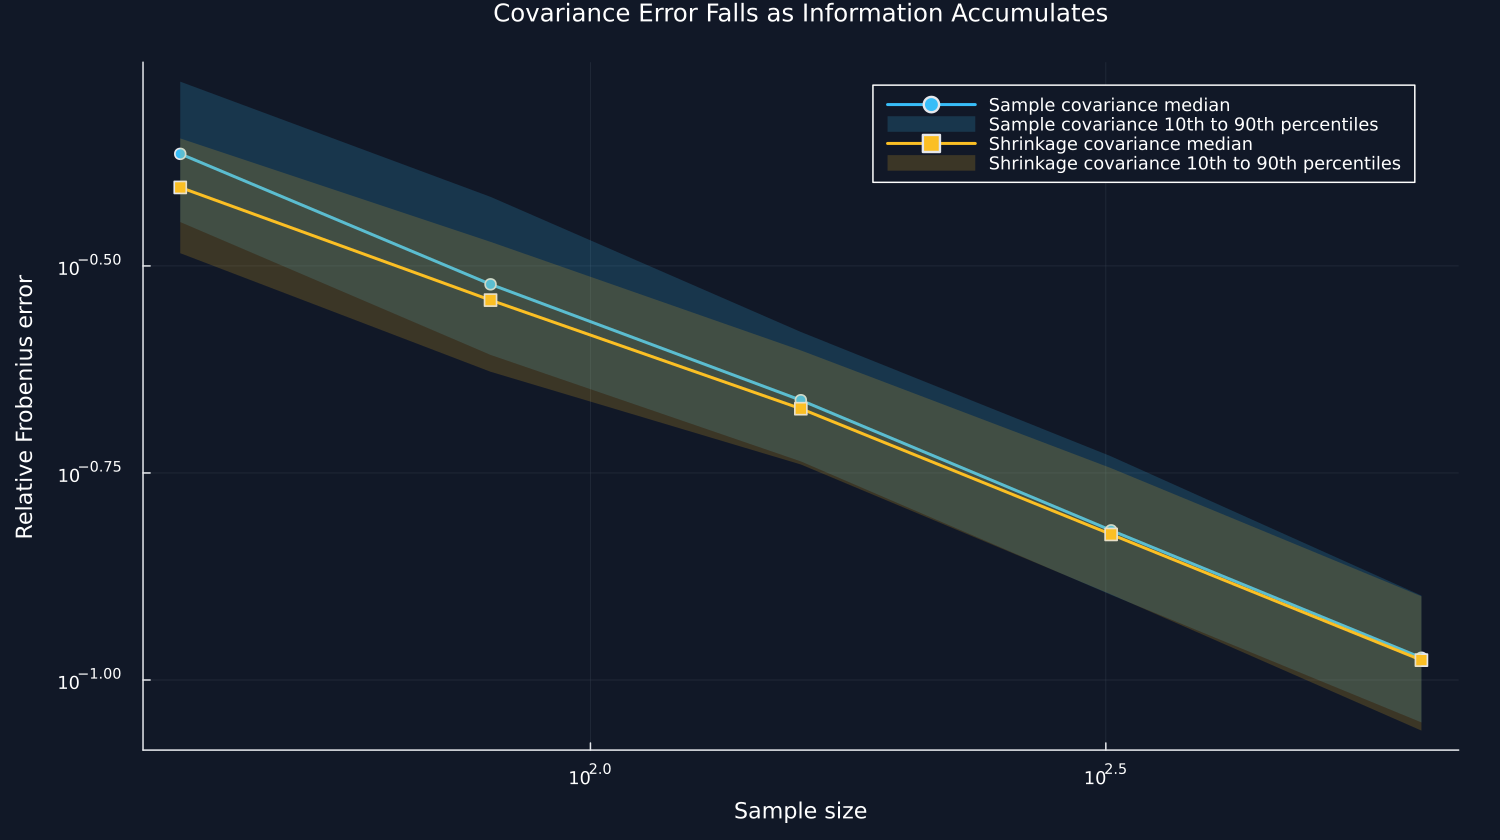

In [5]:
sample_quantiles = reduce(vcat, [permutedims(quantile(group[!, "Sample covariance error"], [0.1, 0.5, 0.9])) for group in groupby(covariance_trials, "Sample size"; sort=true)])
shrinkage_quantiles = reduce(vcat, [permutedims(quantile(group[!, "Shrinkage covariance error"], [0.1, 0.5, 0.9])) for group in groupby(covariance_trials, "Sample size"; sort=true)])
figure = plot(sample_sizes, sample_quantiles[:, 2]; xscale=:log10, yscale=:log10, marker=:circle, color=palette.cyan, label="Sample covariance median", xlabel="Sample size", ylabel="Relative Frobenius error", title="Covariance Error Falls as Information Accumulates", size=(1000, 560), legend=:topright)
plot!(figure, sample_sizes, sample_quantiles[:, 1]; fillrange=sample_quantiles[:, 3], linealpha=0, fillalpha=0.18, color=palette.cyan, label="Sample covariance 10th to 90th percentiles")
plot!(figure, sample_sizes, shrinkage_quantiles[:, 2]; marker=:square, color=palette.amber, label="Shrinkage covariance median")
plot!(figure, sample_sizes, shrinkage_quantiles[:, 1]; fillrange=shrinkage_quantiles[:, 3], linealpha=0, fillalpha=0.18, color=palette.amber, label="Shrinkage covariance 10th to 90th percentiles")
save_data(DataFrame("Sample size"=>sample_sizes, "Sample lower"=>sample_quantiles[:, 1], "Sample median"=>sample_quantiles[:, 2], "Sample upper"=>sample_quantiles[:, 3], "Shrinkage lower"=>shrinkage_quantiles[:, 1], "Shrinkage median"=>shrinkage_quantiles[:, 2], "Shrinkage upper"=>shrinkage_quantiles[:, 3]), paths, "covariance_error_convergence")
save_figure(figure, paths, "covariance_error_convergence")


## Tests

In [6]:
theoretical_eigenvalues = sort(vcat(1+(block_size-1)*within_block_correlation, fill(1-within_block_correlation, block_size-1)))
@assert size(block_correlation) == (dimension, dimension)
@assert block_correlation ≈ block_correlation'
@assert eigvals(Symmetric(block_correlation[1:block_size, 1:block_size])) ≈ theoretical_eigenvalues
@assert minimum(eigvals(Symmetric(block_correlation))) > 0
@assert size(true_mean) == (dimension, 1)
@assert size(true_covariance) == (dimension, dimension)
@assert diag(true_correlation) ≈ ones(dimension)
@assert minimum(eigvals(Symmetric(true_covariance))) > 0
@assert minimum(eigvals(Symmetric(factor_covariance))) > 0
@assert sample_mean == shrinkage_mean
@assert size(sample_covariance) == size(shrinkage_covariance) == size(true_covariance)
@assert all(covariance_trials[!, "Paired means agree"])
@assert nrow(covariance_trials) == length(sample_sizes)*repetitions
@assert covariance_estimation_summary[end, "Median sample covariance error"] < covariance_estimation_summary[1, "Median sample covariance error"]
@assert covariance_estimation_summary[end, "Median shrinkage covariance error"] < covariance_estimation_summary[1, "Median shrinkage covariance error"]
@assert covariance_estimation_summary[1, "Median shrinkage covariance error"] < covariance_estimation_summary[1, "Median sample covariance error"]
@assert all(0 .<= covariance_estimation_summary[!, "Shrinkage improvement frequency"] .<= 1)
